# Which tissues and which stages of *Phallusia* development vary most?

The notebook `phallusia_variability.ipynb` showed that the embryos of the
ascidian *Phallusia mammillata* are reproducible cell by cell: once their
paces are aligned, the same cell differs between two embryos about as much
as between the two sides of one embryo. This notebook asks where that
variability lies. Are some tissues more variable than others? Are some
stages? And, since tissues divide, move and shrink at different times, which
of the two really matters?

The data are the seven curated embryos (v2) of the ASTEC datasets (Guignard
et al., Science 369, eaar5663, 2020), named with the atlas of Biasuz et al.
(bioRxiv, 2025), filmed every two minutes at about 18 °C from the 64-cell
stage. The helper functions are in `ascidian_tools.py`.

**In short.**

- **Time.** The embryos are most alike during the last cleavages, from 64
  to 112 cells. From the onset of gastrulation, the positions of the same
  cells drift apart: for cells of the same size, the variability of their
  positions doubles between 250 and 390 minutes. Contacts become 1.8 times
  more variable over the same period, but only because the cells then have
  more neighbours and more small contacts. Division timing is most precise
  for the divisions of the 64-cell stage and least precise around 330
  minutes, during gastrulation. The variability of volumes rises only
  because the cells become smaller.
- **Tissues.** The ectoderm, and the neural plate above all, is the most
  reproducible. At equal time and size, neural plate cells are 16 to 37%
  less variable in division timing, volume, shape, division orientation,
  position and contacts. The internal tissues (trunk mesoderm, mesenchyme,
  endoderm) are 15 to 40% more variable in contacts, shape or volume, and
  the lineages of the mesenchyme twice as variable. Muscle precursors vary
  in position, but their lineages are the most reproducible, since they stop
  dividing.
- **Robustness.** These effects hold when any one embryo is left out.
  Without the odd B7.7 lineage, the mesenchyme keeps its variable lineages
  and contacts. Swapped sister names are too rare to explain them.
- **Embryo or cell?** A quarter of the variability of contacts between
  embryos, and a third to a half of that of positions, is shared by the two
  sides of an embryo. The rest is as large between the two sides of one
  embryo as between embryos.
- **Timing.** A cell does not inherit the advance or delay of its mother's
  cycle (r = -0.06): timing errors neither accumulate nor get corrected.
  Sisters share them (0.46), and so do bilateral homologues (0.32 to 0.41),
  although their last common ancestor is the zygote. Cells of the same
  tissue deviate together slightly more than cells of different tissues, in
  6 of 7 embryos. Part of the timing variability is therefore set per cell
  type, in each embryo.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

import lineagetree
import ascidian_tools as at

warnings.filterwarnings("ignore", message="More than 100 comparisons")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
print("lineagetree", lineagetree.__version__)

lineagetree 3.3.1


## 1. Seven embryos, one clock

The seven v2 embryos are loaded and aligned in time as in the first
notebook: one linear transformation of time per embryo, fitted on the birth
times of the named cells, with Phmamm-8-v2 as the reference.

In [2]:
V2_FILES = {name: file for name, file in at.EMBRYOS.items() if name.endswith("-v2")}
V2 = list(V2_FILES)
embryos = at.load_embryos(embryos=V2_FILES)
tables = {e: at.cell_table(embryos[e]) for e in V2}
tissues = at.tissue_of(tables)
alignment = at.TimeAlignment(tables, references=dict(embryos))
at.set_time_resolutions(embryos, alignment, V2)
life = at.life_minutes(alignment)
alignment.summary()[["slope", "start (min)", "end (min)", "median |deviation| (min)"]].round(2)

,slope,start (min),end (min),median |deviation| (min)
Phmamm-1-v2,0.75,245.36,513.39,2.64
Phmamm-3-v2,0.91,227.51,389.31,1.94
Phmamm-4-v2,0.90,216.77,376.53,2.54
Phmamm-5-v2,0.86,234.26,387.04,3.19
Phmamm-7-v2,0.88,224.90,361.42,2.55
Phmamm-8-v2,1.00,242.00,416.00,3.12
Phmamm-9-v2,0.96,260.38,379.57,2.12


{'64 cells': 242, '112 cells': 283, '218 cells': 366, 'late neurula': 420}


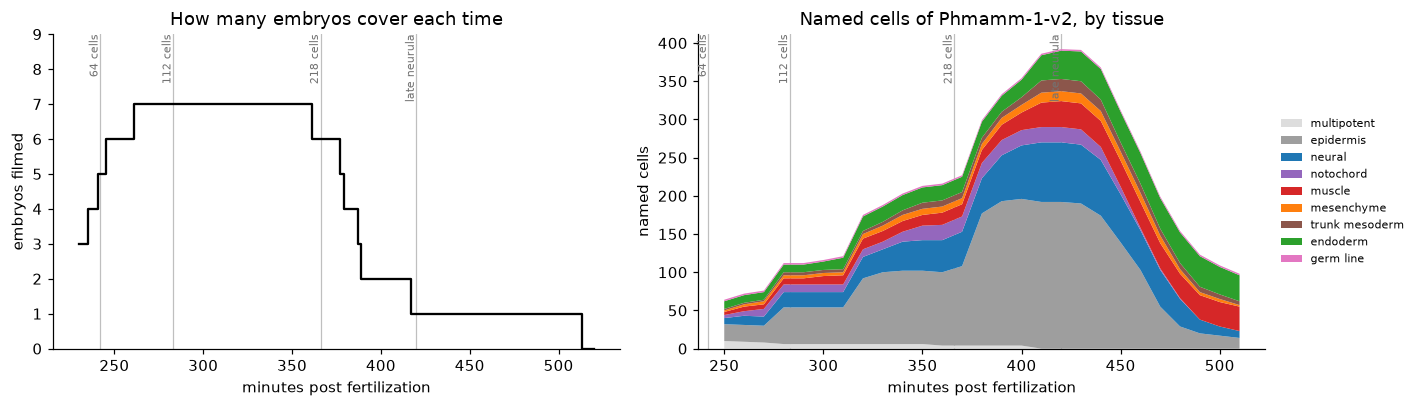

In [3]:
counts = {e: at.cell_counts(embryos[e]) for e in V2}
stages = at.stage_times(at.count_curve(counts, alignment, V2), alignment, [64, 112, 218])
LANDMARKS = {"64 cells": stages[64], "112 cells": stages[112], "218 cells": stages[218], "late neurula": 420.0}
print({k: round(v) for k, v in LANDMARKS.items()})

grid = np.arange(230, 521, 2.0)
reference_grid = (grid - alignment.start_minutes) / alignment.interval
filmed = pd.DataFrame({e: (alignment.coverage[e][0] <= reference_grid) & (reference_grid <= alignment.coverage[e][1])
                       for e in V2}, index=grid)

SNAPSHOTS = np.arange(5, 136, 5)  # reference time points: every 10 minutes from 250 to 510 minutes
P1 = "Phmamm-1-v2"
composition = {}
for tau in SNAPSHOTS:
    names = at.named_nodes(embryos[P1], at.frame_at(alignment, P1, tau))
    composition[alignment.start_minutes + alignment.interval * tau] = (
        tissues.reindex(list(names)).fillna("unknown").replace({"mixed": "multipotent"}).value_counts())
composition = pd.DataFrame(composition).T.fillna(0)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax.step(grid, filmed.sum(axis=1), where="mid", color="k")
at.landmark_lines(ax, LANDMARKS)
ax.set(xlabel="minutes post fertilization", ylabel="embryos filmed", title="How many embryos cover each time",
       ylim=(0, 9))
ORDER = ["multipotent", "epidermis", "neural", "notochord", "muscle", "mesenchyme", "trunk mesoderm", "endoderm",
         "germ line"]
shown = [t for t in ORDER if t in composition]
ax2.stackplot(composition.index, composition[shown].T.values, labels=shown,
              colors=[at.TISSUE_COLORS.get(t, "#dddddd") for t in shown])
at.landmark_lines(ax2, LANDMARKS)
ax2.set(xlabel="minutes post fertilization", ylabel="named cells", title=f"Named cells of {P1}, by tissue")
ax2.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout()
plt.show()

Four landmarks place the stages on the common clock:

- the 64-cell stage;
- the 112-cell stage, which starts gastrulation (stage 10, initial
  gastrula);
- the 218-cell stage, a mid gastrula (Biasuz et al.);
- the late neurula, at about 7 hours post fertilization at 18 °C (Guignard
  et al.).

They come from the median number of cells of the aligned embryos.

The window over which embryos can be compared is short. All seven are
filmed from 262 to 360 minutes, four or more from 236 to 386 minutes, and
only Phmamm-1-v2 after 416 minutes. Comparisons between embryos therefore
stop at about 400 minutes; after that, only the two sides of Phmamm-1-v2
can be compared. The names also thin out after 430 minutes: the daughters
of the cells named last are left unnamed. Most of the cells have a single
tissue among their descendants from the 64-cell stage on. The few that have
several are called *multipotent* here.

## 2. Eight measures of variability

Each measure compares the same cell (same name, same side) in two embryos.
Where possible, it also compares a left cell with its right homologue in
the same embryo. Each comparison gets the tissue of the cell and a time,
in minutes post fertilization on the common clock:

| measure | compares | time |
|---|---|---|
| division time | division times, in minutes | the division |
| cycle length | cycle lengths, in minutes | the middle of the cycle |
| volume | volumes (fraction of the embryo), relative difference | the middle of the cycle |
| shape | elongations (longest over shortest axis), relative difference | the middle of the cycle |
| orientation | angle between the division axes, after registration | the division |
| position | distance after registration, in typical cell radii | every 10 minutes |
| contacts | neighbourhood distance: fraction of the surface touching different cells | every 10 minutes |
| lineage | normalised UTED of the lineages over 80 minutes | the middle of the window |

The lineages are followed from a common start time, every 10 minutes, while
three embryos or more cover the 80 minutes. Shorter windows, or windows
starting at the birth of each cell, mostly measure whether a division falls
inside the window.

In [4]:
division = at.event_minutes(alignment, "division")
cycles = at.cycle_lengths(alignment)
volumes = pd.DataFrame({e: tables[e].volume for e in V2})
elongation = pd.DataFrame({e: tables[e].elongation for e in V2})
sizes = volumes.median(axis=1)

position_rows, contact_rows, neighbour_rows = [], [], []
for tau in SNAPSHOTS:
    minutes = alignment.start_minutes + alignment.interval * tau
    position_rows.append(at.position_deviations(embryos, alignment, tau, V2).assign(minutes=minutes))
    neighbourhoods = at.neighbourhoods_at(embryos, alignment, tau, V2)
    contact_rows.append(at.neighbourhood_comparisons(neighbourhoods).assign(minutes=minutes))
    for e, cells in neighbourhoods.items():
        for name, values in cells.items():
            small = sum(v for k, v in values.items() if k != "outside" and v < 0.05)
            neighbour_rows.append((e, name, minutes, at.count_neighbours(values), small))
positions = pd.concat(position_rows, ignore_index=True).rename(columns={"distance": "difference"})
contacts = pd.concat(contact_rows, ignore_index=True).rename(columns={"distance": "difference"})
neighbour_stats = pd.DataFrame(neighbour_rows, columns=["embryo", "name", "minutes", "neighbours", "small contacts"])

LINEAGE = 40  # reference time points: lineages followed for 80 minutes
lineage_rows = []
for start in range(0, 100, 5):
    covering = [e for e in V2 if at.frame_at(alignment, e, start) is not None
                and at.frame_at(alignment, e, start + LINEAGE) is not None]
    if len(covering) >= 3:
        d = at.lineage_distances(embryos, alignment, start, start + LINEAGE, covering, sides=False)
        lineage_rows.append(d.assign(minutes=alignment.start_minutes + alignment.interval * (start + LINEAGE / 2)))
lineage = pd.concat(lineage_rows, ignore_index=True).rename(columns={"distance": "difference"})

orientation = at.orientation_differences(embryos, alignment, V2)

measures = {
    "division time": at.annotate(at.pair_differences(division), tissues, life.division, sizes),
    "cycle length": at.annotate(at.pair_differences(cycles), tissues, life.middle, sizes),
    "volume": at.annotate(at.pair_differences(volumes, relative=True), tissues, life.middle, sizes),
    "shape": at.annotate(at.pair_differences(elongation, relative=True), tissues, life.middle, sizes),
    "orientation": at.annotate(orientation, tissues, life.division, sizes),
    "position": at.annotate(positions, tissues, None, sizes),
    "contacts": at.annotate(contacts[contacts.comparison != "sisters"], tissues, None, sizes),
    "lineage": at.annotate(lineage, tissues, None, sizes),
}
LABELS = {
    "division time": "difference (min)",
    "cycle length": "difference (min)",
    "volume": "relative difference",
    "shape": "relative difference of elongation",
    "orientation": "angle between the axes (°)",
    "position": "distance (cell radii)",
    "contacts": "neighbourhood distance",
    "lineage": "normalised UTED, 80 min",
}
for name, table in measures.items():
    table["period"] = (table.minutes // 20) * 20 + 10
    table["log size"] = np.log2(table["size"])

overview = {}
for name, table in measures.items():
    between = table[table.comparison == "between embryos"]
    sides = table[table.comparison == "left/right"]
    overview[name] = {
        "cells": table.name.nunique(),
        "comparisons": len(table),
        "from (min)": table.minutes.min(),
        "to (min)": table.minutes.max(),
        "median between embryos": between.difference.median(),
        "median left/right": sides.difference.median() if len(sides) else np.nan,
    }
overview = pd.DataFrame(overview).T
overview["floor (quantization)"] = [
    at.quantization_floor(measures[m][measures[m].comparison == "between embryos"], alignment, events=k)
    if k else np.nan
    for m, k in zip(overview.index, [1, 2, 0, 0, 0, 0, 0, 0])
]
overview.round(3)

,cells,comparisons,from (min),to (min),median between embryos,median left/right,floor (quantization)
division time,447.0,3686.0,254.759,489.436,3.228,3.433,0.523
cycle length,385.0,1831.0,278.117,449.755,1.980,2.000,0.714
volume,756.0,12356.0,216.769,458.740,0.103,0.083,NaN
shape,756.0,12356.0,216.769,458.740,0.106,0.074,NaN
orientation,345.0,5318.0,254.759,429.540,16.724,13.631,NaN
position,718.0,50909.0,250.000,510.000,0.514,0.417,NaN
contacts,692.0,39827.0,250.000,510.000,0.188,0.175,NaN
lineage,181.0,9557.0,280.000,350.000,0.091,NaN,NaN


Events are timed to one time point, about 2 minutes. Even two embryos with
exactly the same timing would differ by a median of 0.5 minutes in division
time and 0.7 minutes in cycle length (the *floor* column). The measured
medians, 3.2 and 2.0 minutes, are well above.

The time points also bias the comparison of the two sides. Within one
embryo, two cells that divide at the same moment fall on the same time
point and differ by exactly 0. Two embryos are sampled on different grids,
so they never do. The left/right baseline is therefore slightly optimistic
for every measure built from time points. For the lineages, it is so
optimistic (a median UTED of exactly 0) that only comparisons between
embryos are used.

### Small cells look more variable

The volume of a cell is measured up to its boundary. If the boundary is
placed with a constant error, the relative error on the volume scales as the
size of the cell to the power -1/3. The relative differences of volume
scale as size to the power -0.23 to -0.25, both between embryos and between
sides. Positions and contacts also differ more for smaller cells. Since the
cells halve at each division, size falls with time and differs between
tissues: it has to be taken into account before comparing either.

In [5]:
rows = {}
for name in ["volume", "shape", "position", "contacts"]:
    table = measures[name]
    for comparison, group in table.groupby("comparison"):
        ok = group.difference > 0
        slope = np.polyfit(group["log size"][ok], np.log2(group.difference[ok]), 1)[0]
        rows[(name, comparison)] = {"slope (log2 difference per log2 size)": slope,
                                    "comparisons": int(ok.sum())}
pd.DataFrame(rows).T.round(2)

slope (log2 difference per log2 size)  comparisons
volume   between embryos                                  -0.23      10375.0
         left/right                                       -0.25       1981.0
shape    between embryos                                  -0.15      10375.0
         left/right                                       -0.15       1981.0
position between embryos                                  -0.28      41545.0
         left/right                                       -0.28       9364.0
contacts between embryos                                  -0.18      32261.0
         left/right                                       -0.25       7566.0

## 3. Variability over developmental time

For each measure, the median over the comparisons of each 20-minute period,
with its 90% confidence interval. The independent units are the embryos, not
the cells: the intervals come from resampling the embryos
(`at.embryo_bootstrap`). Hollow points rest on one or two embryos.

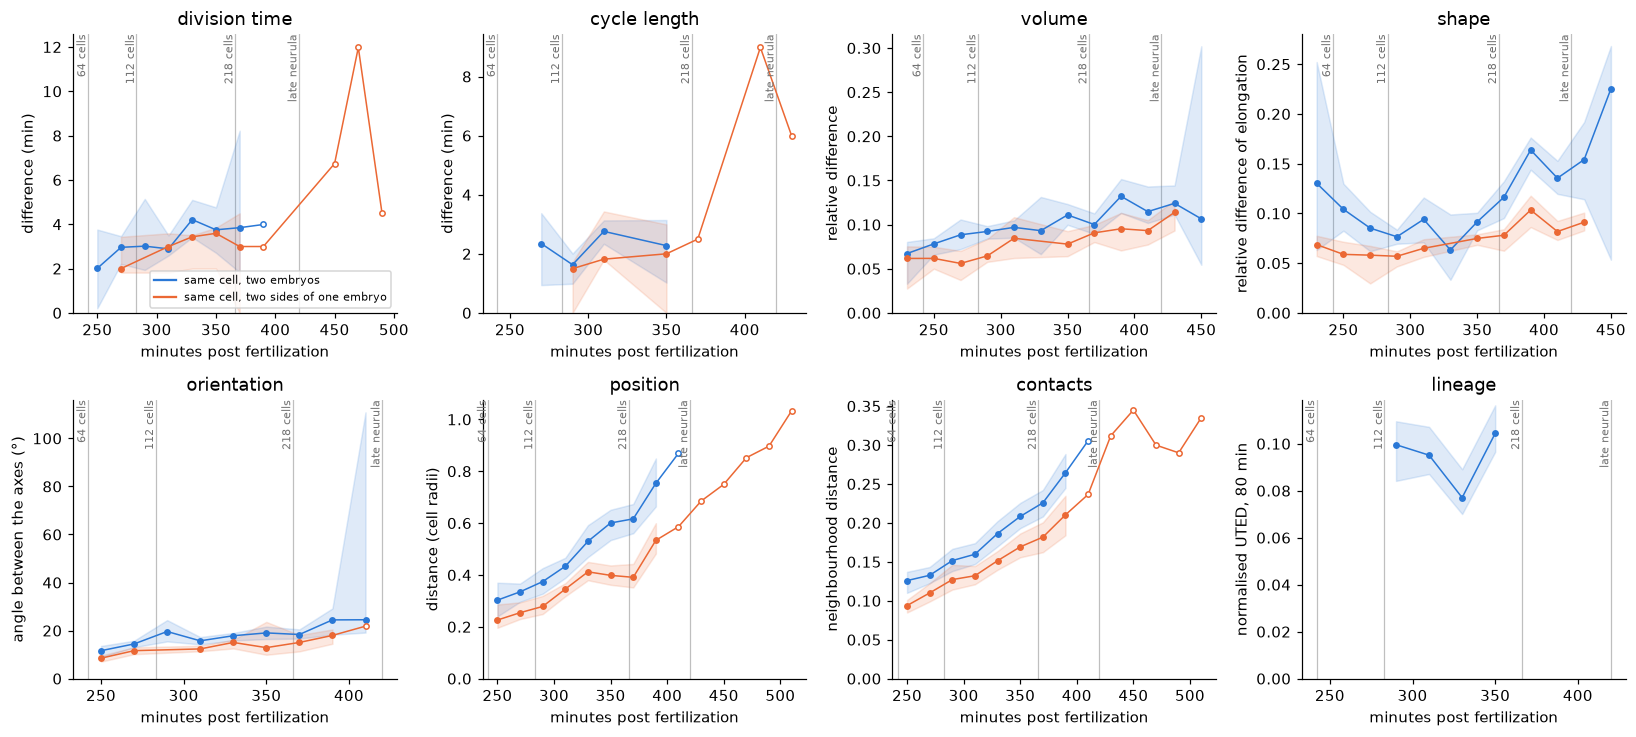

In [6]:
time_profiles, time_draws = {}, {}
for name, table in measures.items():
    time_profiles[name], time_draws[name] = at.embryo_bootstrap(table, ["comparison", "period"])
at.plot_time_profiles(time_profiles, LABELS, LANDMARKS)
plt.show()

In [7]:
EARLY, LATE = (250, 290), (350, 390)
trends = {}
for name, draws in time_draws.items():
    summary = time_profiles[name]
    row = {}
    for comparison in ("between embryos", "left/right"):
        if comparison not in summary.index.get_level_values(0):
            continue
        s = summary.loc[comparison]
        ok = (s.n >= 20) & (s.embryos >= 3)
        early = [p for p in s.index[ok] if EARLY[0] <= p <= EARLY[1]]
        late = [p for p in s.index[ok] if LATE[0] <= p <= LATE[1]]
        if not early or not late:
            continue
        ratio = (draws[[(comparison, p) for p in late]].mean(axis=1)
                 / draws[[(comparison, p) for p in early]].mean(axis=1)).replace([np.inf, -np.inf], np.nan)
        estimate = s.loc[late, "median"].mean() / s.loc[early, "median"].mean()
        low, high = ratio.quantile([0.05, 0.95])
        row[comparison] = f"{estimate:.2f} [{low:.2f}, {high:.2f}]"
    trends[name] = row
print(f"fold change of the median variability, {LATE[0] - 10}-{LATE[1] + 10} min over {EARLY[0] - 10}-{EARLY[1] + 10} min "
      "(90% interval over embryos):")
pd.DataFrame(trends).T

fold change of the median variability, 340-400 min over 240-300 min (90% interval over embryos):


,between embryos,left/right
division time,"1.43 [0.93, 2.11]","1.65 [0.80, 2.22]"
cycle length,"1.14 [0.71, 1.96]","1.34 [1.14, 2.00]"
volume,"1.33 [1.23, 1.46]","1.45 [1.25, 1.56]"
shape,"1.40 [1.18, 1.69]","1.47 [1.35, 1.72]"
orientation,"1.35 [1.16, 1.53]","1.52 [1.22, 2.08]"
position,"1.95 [1.72, 2.20]","1.74 [1.52, 1.96]"
contacts,"1.70 [1.59, 1.86]","1.70 [1.57, 1.85]"
lineage,"1.05 [0.96, 1.22]",NaN


The geometric measures become more variable as development proceeds. From
the 64-to-112-cell period to the mid gastrula, the variability of positions
doubles and that of contacts rises by 1.7, both between embryos and between
sides. Volumes, shapes and division orientations become 1.3 to 1.4 times
more variable. Division and cycle timing rise less, with intervals that
include no change. The lineages over 80 minutes do not change.

The two sides of an embryo drift apart as fast as two embryos. This is not
a matter of embryos diverging as a whole: each cell becomes less precisely
placed, on both sides of every embryo.

Biasuz et al. found that names are less reliable at the 100-, 150- and
280-cell stages (about 275, 317 and 378 minutes here). The profiles show no
peak at these times.

In [8]:
stats = neighbour_stats.groupby(["minutes"])[["neighbours", "small contacts"]].median()
both = contacts[contacts.comparison == "between embryos"].merge(
    neighbour_stats.rename(columns={"neighbours": "n1", "small contacts": "s1"}), on=["embryo", "name", "minutes"]
).merge(
    neighbour_stats.rename(columns={"embryo": "other", "neighbours": "n2", "small contacts": "s2"}),
    on=["other", "name", "minutes"])
both["neighbours"] = (both.n1 + both.n2) / 2
both["small contacts"] = (both.s1 + both.s2) / 2
print("median number of neighbours and share of the surface in small contacts (under 5%), by time:")
print(stats.T.round(2))
for column in ("neighbours", "small contacts"):
    print(f"rank correlation of the neighbourhood distance with the {column}: "
          f"{spearmanr(both[column], both.difference)[0]:.2f}")

median number of neighbours and share of the surface in small contacts (under 5%), by time:
minutes         250.0  260.0  270.0  280.0  290.0  300.0  310.0  320.0  330.0  \
neighbours       5.00   5.00   5.00   5.00   5.00   5.00   6.00   6.00   6.00   
small contacts   0.05   0.06   0.06   0.07   0.06   0.06   0.06   0.09   0.07   

minutes         340.0  ...  420.0  430.0  440.0  450.0  460.0  470.0  480.0  \
neighbours       5.00  ...   6.00   6.00    6.0   6.00   5.00   5.00   5.00   
small contacts   0.07  ...   0.08   0.09    0.1   0.08   0.07   0.06   0.05   

minutes         490.0  500.0  510.0  
neighbours       5.00   5.00   5.00  
small contacts   0.04   0.04   0.03  

[2 rows x 27 columns]
rank correlation of the neighbourhood distance with the neighbours: 0.29
rank correlation of the neighbourhood distance with the small contacts: 0.28


Why do contacts become more variable? Cells keep 5 to 6 neighbours (over 5%
of their surface), but more of their surface goes to small contacts, and
the neighbourhood distance rises with both. Section 6 checks whether this
explains the trend.

## 4. Variability by tissue

The same medians by tissue, over 260 to 360 minutes, when four embryos or
more are compared. The grey line is the median over tissues.

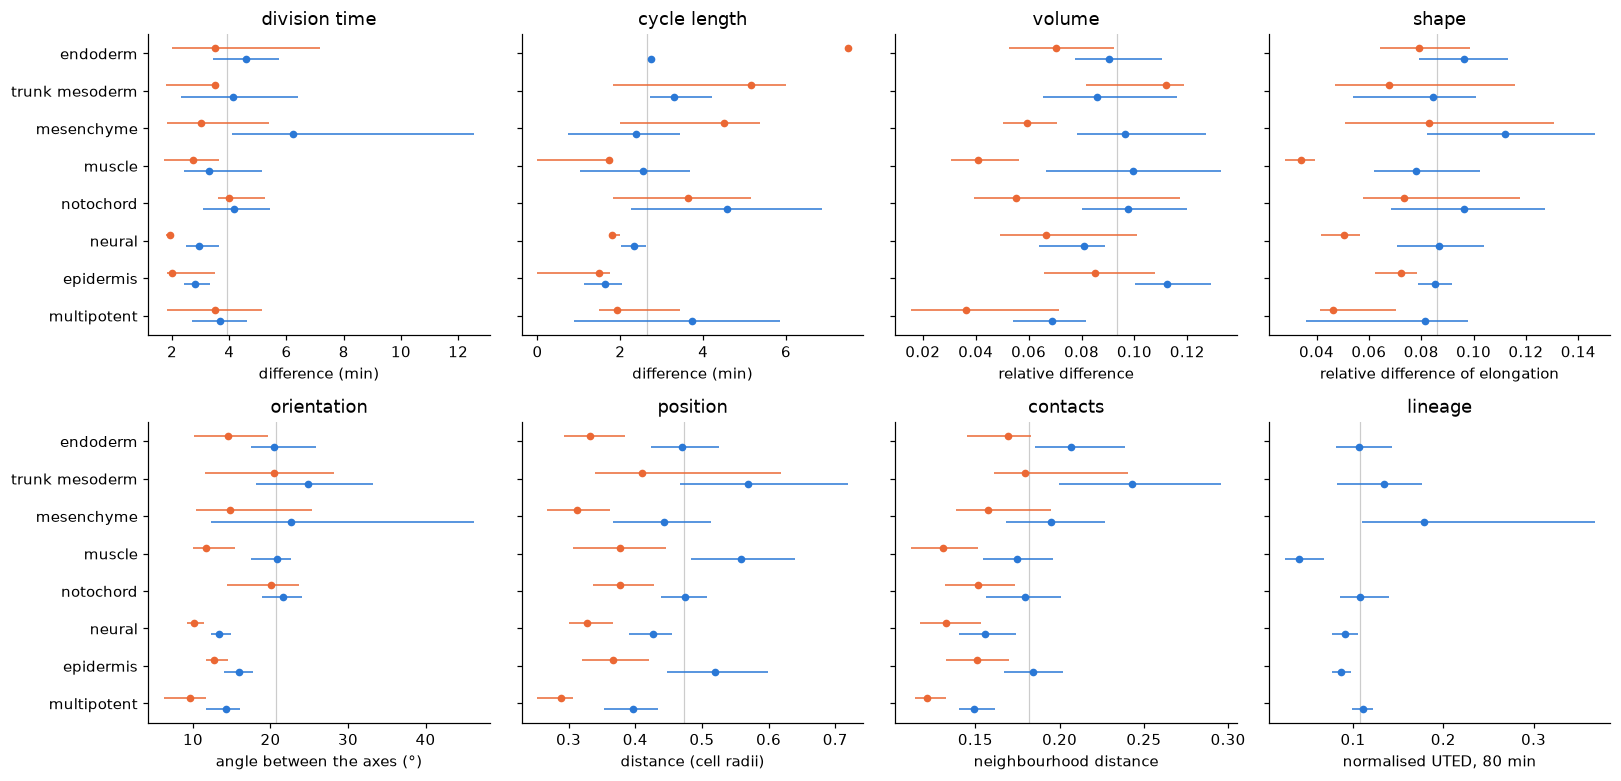

In [9]:
WINDOW = (260, 360)  # minutes: four embryos or more
TISSUES = ["multipotent", "epidermis", "neural", "notochord", "muscle", "mesenchyme", "trunk mesoderm", "endoderm"]
tissue_profiles = {}
for name, table in measures.items():
    kept = table[table.minutes.between(*WINDOW) & table.tissue.isin(TISSUES)]
    tissue_profiles[name] = at.embryo_bootstrap(kept, ["comparison", "tissue"])[0]
at.plot_tissue_profiles(tissue_profiles, LABELS, TISSUES)
plt.show()

Three patterns stand out:

- **Neural plate.** With the epidermis, it is the most precise in division
  timing (3.0 and 2.8 minutes between embryos). It is also the most
  precise in division orientation (13°, against 20 to 25° for the mesoderm
  and endoderm), position and contacts. This agrees with Biasuz et
  al., who found the orientations of the neural plate significantly less
  variable than those of other tissues.
- **Trunk mesoderm.** It is the least precise in position (0.57 cell radii,
  with the muscle precursors) and contacts (24% of the surface, against 15
  to 16% for multipotent and neural plate cells).
- **Mesenchyme.** It has the most variable division times (6.2 minutes) and
  lineages, largely because of B7.7 (first notebook).

But tissues differ in when they divide and how large their cells are, and
both change the variability (sections 2 and 3). The next sections separate
the three.

## 5. Tissue and time together

Each tissue compared with all the cells at the same time: the log2 fold
change of its median variability between embryos over that of all the cells
in the same 20-minute period. Red is more variable, blue less, grey too
few data (under 10 comparisons or 3 embryos).

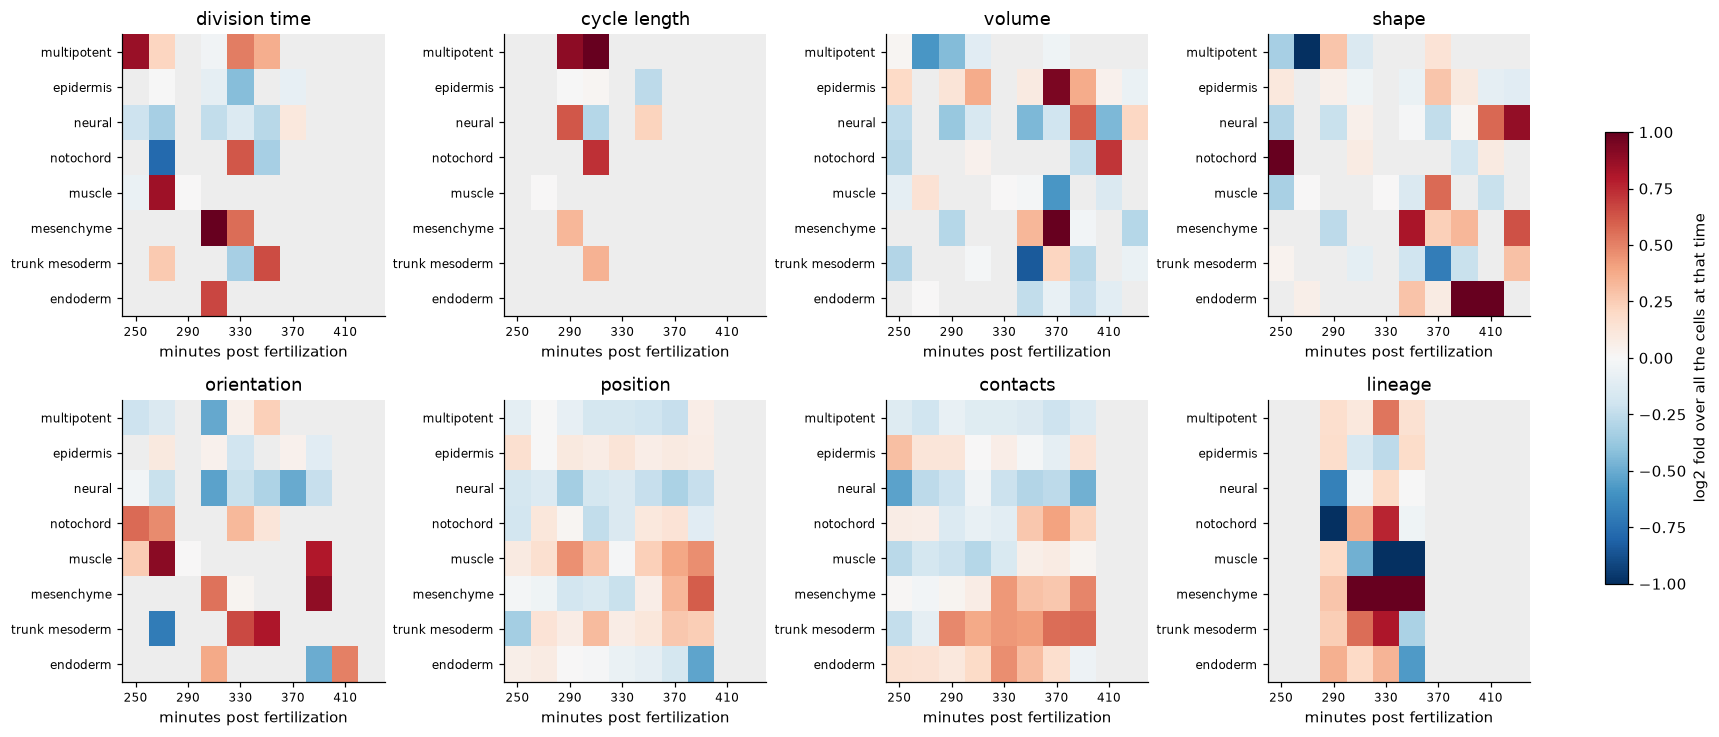

In [10]:
maps = {}
for name, table in measures.items():
    between = table[(table.comparison == "between embryos") & table.tissue.isin(TISSUES)]
    grouped = between.groupby(["tissue", "period"])
    medians = grouped.difference.median()
    seen = pd.concat([between[["tissue", "period", "embryo"]],
                      between[["tissue", "period", "other"]].rename(columns={"other": "embryo"})])
    enough = (grouped.size() >= 10) & (seen.groupby(["tissue", "period"]).embryo.nunique() >= 3)
    overall = between.groupby("period").difference.median()
    fold = np.log2(medians[enough] / overall.reindex(medians[enough].index.get_level_values("period")).values)
    maps[name] = fold.unstack().reindex(columns=np.arange(250, 431, 20))
at.plot_tissue_time(maps, TISSUES)
plt.show()

The differences between tissues persist through time:

- **Neural plate:** below the other cells in position, contacts and
  orientation in almost every period.
- **Trunk mesoderm and mesenchyme:** above in contacts from 310 and 330
  minutes on, during gastrulation.
- **Muscle precursors:** move apart in position late in gastrulation.

The timing measures are patchier, since each period holds a single wave of
divisions.

## 6. Separating tissue, time and size

For each measure, the comparisons between embryos are averaged by cell and
20-minute period. The logarithm of the result is then modelled as the sum
of a tissue effect, a period effect and a linear effect of the logarithm of
the cell size (`at.adjusted_effects`). The model uses the periods from 250
to 390 minutes that at least three embryos compare. A tissue effect of 0.8
means that the cells of that tissue are 20% less variable than the average
tissue, at the same time and size. Intervals are 90%, over resampled
embryos; filled points exclude 1.

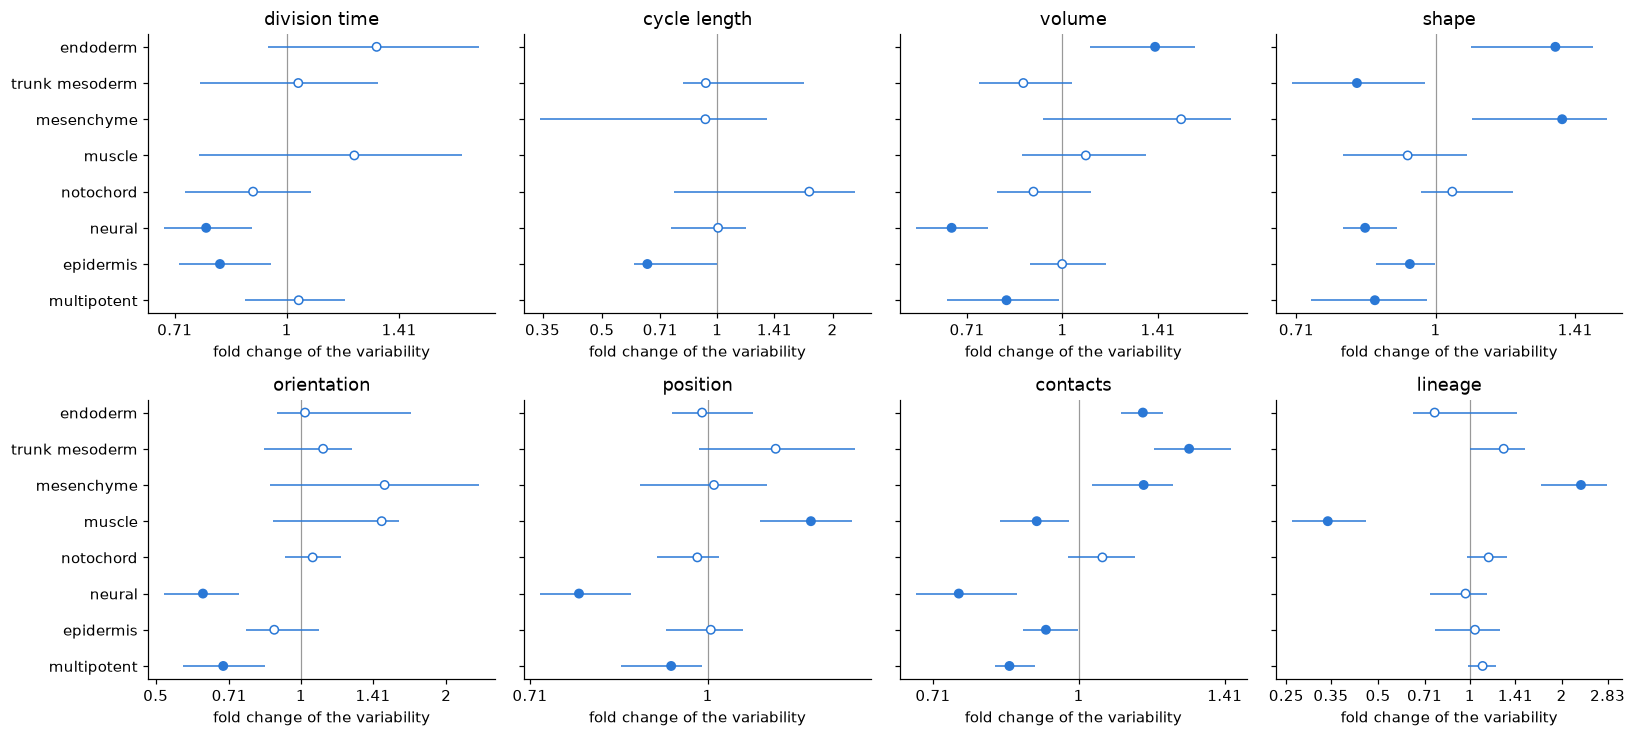

In [11]:
PERIODS = (250, 390)  # 20-minute periods compared by at least three embryos
model_data = {}
for name, table in measures.items():
    between = table[(table.comparison == "between embryos") & table.period.between(*PERIODS)]
    seen = pd.concat([between[["period", "embryo"]], between[["period", "other"]].rename(columns={"other": "embryo"})])
    per_period = seen.groupby("period").embryo.nunique()
    model_data[name] = between[between.period.isin(per_period[per_period >= 3].index)]
effects = {name: at.adjusted_effects(data[data.tissue.isin(TISSUES)], ["tissue", "period"], covariates=["log size"])
           for name, data in model_data.items()}
at.plot_effects(effects, "tissue", order=TISSUES)
plt.show()

In [12]:
tissue_effects = pd.DataFrame({
    name: e[e.factor == "tissue"].set_index("level").apply(
        lambda r: f"{r.fold:.2f}{'*' if r.low > 1 or r.high < 1 else ''}", axis=1)
    for name, e in effects.items()}).reindex(TISSUES)
size_effects = pd.Series({name: e[e.factor == "log size"].iloc[0] for name, e in effects.items()})
print("fold change of the variability when the cell is twice as large (90% interval):")
print({n: f"{r.fold:.2f} [{r.low:.2f}, {r.high:.2f}]" for n, r in size_effects.items()})
print("\nfold change by tissue, the time and the size of the cells being equal (*: 90% interval excludes 1):")
tissue_effects

fold change of the variability when the cell is twice as large (90% interval):
{'division time': '1.05 [0.86, 1.41]', 'cycle length': '1.27 [0.92, 1.84]', 'volume': '0.68 [0.61, 0.80]', 'shape': '0.93 [0.87, 1.01]', 'orientation': '0.97 [0.83, 1.14]', 'position': '0.92 [0.90, 0.95]', 'contacts': '0.95 [0.93, 0.98]', 'lineage': '1.03 [0.86, 1.23]'}

fold change by tissue, the time and the size of the cells being equal (*: 90% interval excludes 1):


,division time,cycle length,volume,shape,orientation,position,contacts,lineage
level,,,,,,,,
multipotent,1.04,NaN,0.82*,0.86*,0.69*,0.93*,0.85*,1.10
epidermis,0.82*,0.66*,1.00,0.94*,0.88,1.01,0.93*,1.04
neural,0.78*,1.01,0.67*,0.84*,0.63*,0.78*,0.75*,0.97
notochord,0.90,1.74,0.90,1.04,1.06,0.98,1.06,1.15
muscle,1.23,NaN,1.09,0.93,1.47,1.22*,0.91*,0.34*
mesenchyme,NaN,0.93,1.53,1.37*,1.49,1.01,1.17*,2.31*
trunk mesoderm,1.04,0.93,0.87,0.82*,1.11,1.14,1.30*,1.29
endoderm,1.32,NaN,1.40*,1.34*,1.02,0.99,1.16*,0.77


Size matters for volumes (a cell twice as large is 32% less variable in
volume), and slightly for positions and contacts (5 to 8%). It does not
matter for timing. With size and time equal, the tissues still differ:

- **Neural plate:** less variable in six of the eight measures, by 16 to
  37%.
- **Epidermis:** precise in timing (division time 0.82, cycle length 0.66).
- **Multipotent cells:** early cells of generations 6 to 8, precise in
  volume, shape, orientation, position and contacts.
- **Endoderm:** more variable in volume (1.40), shape (1.34) and contacts
  (1.16).
- **Trunk mesoderm:** more variable in contacts (1.30).
- **Mesenchyme:** more variable in shape (1.37), contacts (1.17) and above
  all lineage (2.31).
- **Muscle:** more variable in position (1.22), but with the most
  reproducible lineages (0.34), because its cells stop dividing during the
  window.
- **Notochord:** no different from the average.

There are too few mesenchyme divisions in the periods of the model to
estimate their timing effect.

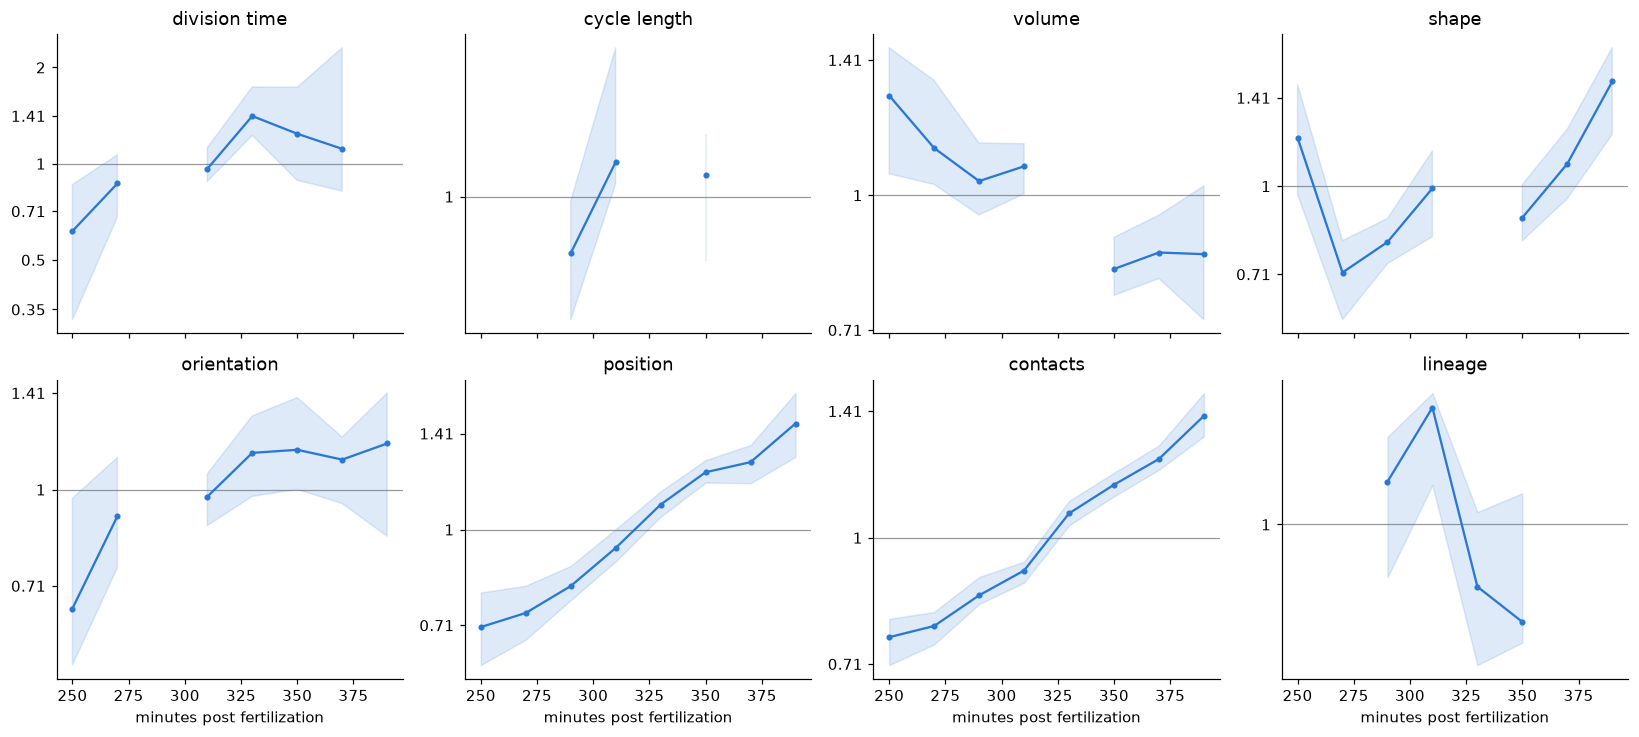

In [13]:
at.plot_effects(effects, "period")
plt.show()

The period effects, for the same tissue and size:

- **Positions:** the clearest trend, 0.71 at 250 minutes to 1.46 at 390
  minutes, twice as variable.
- **Contacts:** 0.76 to 1.39.
- **Division timing:** most precise for the divisions of the 64-cell stage
  (0.62 at 250 minutes), least at 330 minutes (1.41), during gastrulation.
- **Orientations:** a similar step, from 0.65 to about 1.15 after 330
  minutes, as Biasuz et al. found from generation 7 to 8.
- **Shapes:** most reproducible at 270 to 290 minutes, during the early
  gastrula, and most variable at 390 minutes, as neurulation starts.
- **Volumes:** for the same cell size, slightly *less* variable late. The
  raw increase of section 3 is entirely a matter of size.

In [14]:
contact_table = at.annotate(both, tissues, None, sizes)
contact_table["period"] = (contact_table.minutes // 20) * 20 + 10
contact_table["log size"] = np.log2(contact_table["size"])
contact_table = contact_table[contact_table.tissue.isin(TISSUES) & contact_table.period.between(250, 390)]
plain = at.adjusted_effects(contact_table, ["tissue", "period"], covariates=["log size"])
composition_effects = at.adjusted_effects(contact_table, ["tissue", "period"],
                                          covariates=["log size", "neighbours", "small contacts"])
compare = pd.concat({"size only": plain.set_index(["factor", "level"]).fold,
                     "size, neighbours, small contacts": composition_effects.set_index(["factor", "level"]).fold}, axis=1)
compare.round(2)

size only  size, neighbours, small contacts
factor         level                                                      
tissue         endoderm             1.16                              1.07
               epidermis            0.93                              1.00
               mesenchyme           1.17                              0.98
               multipotent          0.85                              0.89
               muscle               0.91                              1.03
               neural               0.75                              0.83
               notochord            1.06                              1.07
               trunk mesoderm       1.30                              1.18
period         250.0                0.76                              1.02
               270.0                0.79                              0.97
               290.0                0.86                              0.93
               310.0                0.91                              0.94
               330.0                1.07                              0.98
               350.0                1.15                              1.03
               370.0                1.24                              1.07
               390.0                1.39                              1.06
log size                            0.95                              0.82
neighbours                           NaN                              1.11
small contacts                       NaN                             11.86

Adding the number of neighbours and the share of the surface in small
contacts to the model of the contacts (both averaged over the two embryos
compared) flattens the period effects, to between 0.93 and 1.07. Contacts
do not become less reproducible as such. The cells grow more and smaller
contacts, and small contacts are the variable ones (first notebook). The
tissue effects shrink but keep their order: the neural plate at 0.83, the
trunk mesoderm at 1.18.

## 7. Variability of the embryo or of the cell?

If an embryo differs from another as a whole, its two sides should differ
from the other embryo together. With squared differences (between embryos,
B; between the two sides of an embryo, LR), the share of the variance that
is embryo-wide is 1 - LR/B. This assumes the two sides vary independently
and equally in each embryo. The share is computed only for the
non-temporal measures, since the time points bias the left/right timing
comparisons.

In [15]:
CONTINUOUS = ["volume", "shape", "orientation", "position", "contacts"]
share_rows = {}
for name in CONTINUOUS:
    table = measures[name]
    table = table[table.minutes.between(*WINDOW) & table.tissue.isin(TISSUES)].assign(
        squared=lambda t: t.difference ** 2)
    for level in ("tissue", "period"):
        summary, draws = at.embryo_bootstrap(table, ["comparison", level], value="squared", statistic="mean")
        for key in summary.loc["between embryos"].index:
            if (("left/right", key) not in draws) or summary.loc[("left/right", key), "embryos"] < 3:
                continue
            share = 1 - draws[("left/right", key)] / draws[("between embryos", key)]
            estimate = 1 - summary.loc[("left/right", key), "median"] / summary.loc[("between embryos", key), "median"]
            share_rows[(name, level, key)] = {"share": estimate, "low": share.quantile(0.05),
                                              "high": share.quantile(0.95)}
shares = pd.DataFrame(share_rows).T
shares.index.names = ["measure", "by", "level"]
shown = shares.apply(lambda r: f"{r.share:.2f} [{r.low:.2f}, {r.high:.2f}]", axis=1)
print("share of the variance between embryos not found between the two sides of an embryo (90% interval):")
print(shown.xs("period", level="by").unstack(0)[CONTINUOUS].to_string())
shown.xs("tissue", level="by").unstack(0).reindex(TISSUES)[CONTINUOUS]

share of the variance between embryos not found between the two sides of an embryo (90% interval):
measure             volume              shape          orientation           position           contacts
level                                                                                                   
270.0    0.40 [0.13, 0.59]  0.48 [0.22, 0.69]  -0.05 [-0.24, 0.19]  0.32 [0.18, 0.45]  0.23 [0.13, 0.33]
290.0    0.22 [0.09, 0.37]  0.26 [0.07, 0.44]    0.63 [0.23, 0.84]  0.30 [0.15, 0.44]  0.18 [0.11, 0.25]
310.0    0.30 [0.14, 0.48]  0.33 [0.01, 0.52]    0.27 [0.06, 0.50]  0.29 [0.15, 0.40]  0.20 [0.15, 0.26]
330.0    0.78 [0.45, 0.90]  0.74 [0.60, 0.86]   0.22 [-0.24, 0.44]  0.30 [0.11, 0.45]  0.27 [0.17, 0.38]
350.0    0.46 [0.27, 0.58]  0.34 [0.21, 0.44]   0.12 [-0.19, 0.41]  0.44 [0.32, 0.54]  0.27 [0.19, 0.35]
370.0                  NaN                NaN                  NaN  0.45 [0.34, 0.55]  0.27 [0.21, 0.34]


measure,volume,shape,orientation,position,contacts
level,,,,,
multipotent,"0.12 [-0.44, 0.63]","0.57 [0.29, 0.73]","0.27 [0.12, 0.43]","0.52 [0.45, 0.57]","0.23 [0.16, 0.28]"
epidermis,"0.29 [0.18, 0.42]","0.29 [0.15, 0.42]","0.21 [-0.03, 0.42]","0.35 [0.15, 0.52]","0.23 [0.14, 0.34]"
neural,"0.17 [-0.07, 0.41]","0.50 [0.34, 0.63]","0.46 [0.23, 0.57]","0.38 [0.28, 0.46]","0.22 [0.16, 0.29]"
notochord,"0.41 [0.04, 0.73]","0.25 [-0.29, 0.50]","-0.07 [-0.35, 0.24]","0.33 [0.18, 0.51]","0.22 [0.10, 0.35]"
muscle,"0.75 [0.42, 0.88]","0.63 [0.32, 0.78]","0.09 [-0.52, 0.74]","0.51 [0.28, 0.67]","0.26 [0.05, 0.47]"
mesenchyme,"0.90 [0.81, 0.96]","0.46 [0.17, 0.71]","0.59 [0.02, 0.88]","0.49 [0.37, 0.60]","0.30 [0.13, 0.48]"
trunk mesoderm,"-0.13 [-0.51, 0.14]","-0.55 [-1.17, 0.19]","-0.04 [-0.27, 0.18]","0.23 [0.05, 0.46]","0.22 [0.02, 0.38]"
endoderm,"0.24 [0.09, 0.44]","0.21 [-0.30, 0.64]","0.22 [-0.07, 0.69]","0.41 [0.24, 0.55]","0.37 [0.20, 0.49]"


For contacts, about a quarter of the variance between embryos is embryo-wide
(0.18 to 0.37), at every time and in every tissue. The remaining three
quarters are as large between the two sides of one embryo. For positions, the
embryo-wide share is a third until 330 minutes and rises to 0.45 at 350 to
370 minutes: the embryos begin to differ in their overall shape as
neurulation approaches. A few tissues stand out:

- **Mesenchyme volumes:** 90% embryo-wide, the unequal or equal division
  of B7.7, chosen once for both sides of Phmamm-5-v2.
- **Muscle volumes:** 75% embryo-wide.
- **Trunk mesoderm volumes and shapes:** the share is negative, the two
  sides of an embryo differing *more* than embryos. Either it reflects a
  systematic difference between the left and right trunk mesoderm, or it is
  noise on a small group of 14 cells.

In [16]:
deviation = alignment.deviations("division")
bins = (life.division.reindex(deviation.index) // 20) * 20 + 10
embryo_shift = deviation.groupby(bins).median()
residual = deviation - embryo_shift.reindex(bins.values).set_axis(deviation.index)
clock = pd.DataFrame({
    "observations": deviation.notna().groupby(bins).sum().sum(axis=1),
    "SD of the embryo medians (min)": embryo_shift.std(axis=1),
    "robust SD of the cells around them (min)": residual.stack().groupby(
        lambda k: bins[k[0]]).apply(lambda s: 1.4826 * (s - s.median()).abs().median()),
})
clock[clock.observations >= 30].round(2)

,observations,SD of the embryo medians (min),robust SD of the cells around them (min)
250.0,32,2.32,1.98
270.0,232,1.19,3.22
310.0,450,0.44,3.35
330.0,173,1.86,4.68
350.0,74,1.62,4.12
370.0,194,2.39,4.41
390.0,89,2.11,4.83


For timing, the same question has a simpler answer. A linear clock leaves
each embryo slightly early or late in each 20-minute period: the median
deviation of its divisions in that period. These embryo-wide shifts vary
by 0.4 to 2.4 minutes between embryos, against 2 to 5 minutes for the
cells around them. The cell-level spread grows from 2.0 minutes at 250
minutes to 4 to 5 minutes from 330 minutes on. Timing variability is
mostly cell by cell, and it rises during gastrulation.

## 8. Timing: inherited, shared or coordinated?

The deviation of a cell in an embryo is its value minus its median over the
embryos. How do the deviations of related cells of the same embryo compare?

- **Mother and daughter:** if timing errors accumulated along lineages,
  the cycle of a daughter would deviate with that of its mother. If they
  were corrected, it would deviate against it.
- **Sisters and bilateral homologues:** these are born at the same time.
- **More distant kin, beyond cousins:** compared within the same tissue or
  across tissues, for cells of the same generation dividing within 10
  minutes of each other. The median deviation of the embryo in each
  20-minute period is removed first, so that an embryo-wide shift does not
  count.

In [17]:
kin = {}
for label, values, times in (("cycle length", cycles, life.birth), ("division time", division, life.division)):
    for relation in ("mother", "sister", "homologue"):
        pairs = at.related_deviations(values, relation)
        if len(pairs) > 20:
            kin[(label, relation)] = {"pairs": len(pairs), "correlation": np.corrcoef(pairs["first"], pairs["second"])[0, 1]}
print("correlation of the deviations of related cells of the same embryo:")
print(pd.DataFrame(kin).T.round(2))
coordination = {label: at.deviation_correlations(values, tissues, times, by_embryo=True)
                for label, values, times in (("cycle length", cycles, life.birth),
                                             ("division time", division, life.division))}
table = pd.concat({k: v.pivot(index="class", columns="embryo", values="correlation") for k, v in coordination.items()})
for label in coordination:
    same, different = table.loc[(label, "same tissue")], table.loc[(label, "different tissues")]
    print(f"{label}: same tissue {same.mean():.2f}, different tissues {different.mean():.2f} on average; "
          f"same tissue higher in {(same > different).sum()} of {(same.notna() & different.notna()).sum()} embryos")
table.round(2)

correlation of the deviations of related cells of the same embryo:
                          pairs  correlation
cycle length  mother      509.0        -0.06
              sister      524.0         0.46
              homologue   535.0         0.32
division time mother     1101.0         0.47
              sister      759.0         0.39
              homologue   781.0         0.41


cycle length: same tissue 0.11, different tissues -0.04 on average; same tissue higher in 4 of 6 embryos
division time: same tissue 0.20, different tissues 0.03 on average; same tissue higher in 6 of 7 embryos


embryo                           Phmamm-1-v2  Phmamm-3-v2  Phmamm-4-v2  \
              class                                                      
cycle length  cousins                   0.11         0.19         0.25   
              different tissues         0.04        -0.20         0.04   
              left/right                0.33         0.74         0.60   
              same tissue               0.03         0.13         0.31   
              sisters                   0.19         0.74         0.68   
division time cousins                   0.58         0.27         0.69   
              different tissues        -0.00         0.07         0.18   
              left/right                0.28         0.30         0.52   
              same tissue               0.02        -0.02         0.51   
              sisters                   0.51         0.73         0.88   

embryo                           Phmamm-5-v2  Phmamm-7-v2  Phmamm-8-v2  \
              class                                                      
cycle length  cousins                  -0.33         0.09        -0.05   
              different tissues        -0.08        -0.05        -0.01   
              left/right                0.03        -0.07         0.19   
              same tissue               0.20        -0.06         0.02   
              sisters                   0.41         0.28         0.41   
division time cousins                  -0.01         0.77         0.68   
              different tissues        -0.15         0.16        -0.02   
              left/right                0.78         0.13         0.44   
              same tissue               0.18         0.40         0.07   
              sisters                   0.59         0.50         0.84   

embryo                           Phmamm-9-v2  
              class                           
cycle length  cousins                    NaN  
              different tissues          NaN  
              left/right                 NaN  
              same tissue                NaN  
              sisters                    NaN  
division time cousins                   0.21  
              different tissues        -0.01  
              left/right                0.36  
              same tissue               0.26  
              sisters                   0.54

Cycle lengths are not inherited: the cycle of a daughter does not deviate
with that of its mother (r = -0.06). Timing errors neither accumulate along
lineages nor get compensated. Division *times* correlate between mother and
daughter (0.47) only because a daughter is born when its mother divides.

Sisters share their deviations (0.46 for cycles, 0.39 for division times).
So do bilateral homologues (0.32 and 0.41), although their last common
ancestor is the zygote. In a given embryo, a cell and its
mirror image divide early or late together. Cells of the same tissue that
are not close kin also deviate together slightly more than cells of
different tissues (0.20 against 0.03 for division times), and this holds in
6 of the 7 embryos. Part of the timing variability is set per cell type in
each embryo, perhaps by the inductive signals the cells receive, rather than
cell by cell or embryo by embryo.

## 9. Robustness

**One embryo at a time.** The model is refitted without each embryo in turn
(with fewer resamplings). The range of the tissue fold changes:

In [18]:
leave_one_out = {}
for name, data in model_data.items():
    between = data[data.tissue.isin(TISSUES)]
    folds = {}
    for e in V2:
        subset = between[(between.embryo != e) & (between.other != e)]
        result = at.adjusted_effects(subset, ["tissue", "period"], covariates=["log size"], draws=50)
        folds[e] = result[result.factor == "tissue"].set_index("level").fold
    folds = pd.DataFrame(folds)
    leave_one_out[name] = folds.apply(lambda r: f"{r.min():.2f}-{r.max():.2f}", axis=1)
print("range of the tissue fold changes when each embryo is left out in turn:")
pd.DataFrame(leave_one_out).reindex(TISSUES)

range of the tissue fold changes when each embryo is left out in turn:


,division time,cycle length,volume,shape,orientation,position,contacts,lineage
level,,,,,,,,
multipotent,0.94-1.08,NaN,0.76-0.88,0.77-0.89,0.65-0.77,0.88-0.97,0.83-0.87,0.99-1.15
epidermis,0.79-0.87,0.63-0.73,0.96-1.07,0.91-0.98,0.83-0.93,0.96-1.03,0.89-0.96,0.92-1.14
neural,0.71-0.82,0.81-1.05,0.63-0.71,0.81-0.86,0.58-0.70,0.76-0.83,0.72-0.78,0.89-1.04
notochord,0.83-0.96,1.58-1.96,0.85-0.95,1.02-1.08,0.97-1.11,0.94-1.00,1.00-1.10,1.09-1.21
muscle,0.98-1.44,NaN,1.02-1.17,0.88-1.00,1.18-1.53,1.16-1.25,0.86-0.93,0.30-0.38
mesenchyme,NaN,0.93-1.03,1.34-1.64,1.28-1.43,1.10-1.64,0.95-1.07,1.11-1.21,1.93-2.53
trunk mesoderm,0.90-1.11,0.82-1.00,0.83-0.93,0.76-0.89,1.00-1.18,1.03-1.19,1.22-1.34,1.13-1.38
endoderm,1.11-1.57,NaN,1.29-1.54,1.29-1.39,0.95-1.26,0.95-1.02,1.13-1.19,0.69-1.01


Every effect that excludes 1 above stays on the same side of 1 whichever
embryo is left out.

**Without B7.7.** B7.7 divides unequally in most embryos and equally in
Phmamm-5-v2 and on one side of Phmamm-9-v2 (first notebook). Is the
mesenchyme variable only because of it?

In [19]:
B77 = ("b7.0007_", "b7.0007*")
in_b77 = {n for t in tables.values() for n in t.index if any(n == r or at.is_ancestor(r, n) for r in B77)}
rows = {}
for name, data in model_data.items():
    between = data[data.tissue.isin(TISSUES)]
    without = at.adjusted_effects(between[~between.name.isin(in_b77)], ["tissue", "period"], covariates=["log size"])
    row = {}
    for label, result in (("mesenchyme, all cells", effects[name]), ("without the B7.7 lineage", without)):
        found = result[(result.factor == "tissue") & (result.level == "mesenchyme")]
        row[label] = "too few cells" if found.empty else "{:.2f} [{:.2f}, {:.2f}]".format(
            *found.iloc[0][["fold", "low", "high"]])
    rows[name] = row
print(f"{len(in_b77)} cell names in the B7.7 lineage, on both sides")
pd.DataFrame(rows).T

10 cell names in the B7.7 lineage, on both sides


,"mesenchyme, all cells",without the B7.7 lineage
division time,too few cells,too few cells
cycle length,"0.93 [0.34, 1.35]","0.84 [0.34, 1.26]"
volume,"1.53 [0.93, 1.83]","1.30 [0.80, 1.67]"
shape,"1.37 [1.09, 1.52]","1.29 [0.96, 1.53]"
orientation,"1.49 [0.86, 2.34]","1.61 [0.82, 2.33]"
position,"1.01 [0.88, 1.12]","1.12 [0.87, 1.28]"
contacts,"1.17 [1.03, 1.25]","1.19 [1.05, 1.27]"
lineage,"2.31 [1.71, 2.81]","2.37 [1.28, 3.44]"


Without the 10 cell names of the B7.7 lineage, the mesenchyme keeps its
highly variable lineages (2.37) and contacts (1.19). Its other mesenchyme
lineage, B8.5, is variable too (section 10).

**Founder lines and germ layers.** The same model with the four founder
lines (a, b: animal; A, B: vegetal) or the germ layers instead of the
tissues:

In [20]:
line_effects = {name: at.adjusted_effects(data, ["line", "period"], covariates=["log size"])
                for name, data in model_data.items()}
LAYERS = {"epidermis": "ectoderm", "neural": "ectoderm", "notochord": "mesoderm", "muscle": "mesoderm",
          "mesenchyme": "mesoderm", "trunk mesoderm": "mesoderm", "endoderm": "endoderm", "multipotent": "multipotent"}
layer_effects = {name: at.adjusted_effects(data[data.tissue.isin(TISSUES)].assign(layer=lambda t: t.tissue.map(LAYERS)),
                                          ["layer", "period"], covariates=["log size"])
                 for name, data in model_data.items()}
pd.concat({
    "founder line": pd.DataFrame({name: e[e.factor == "line"].set_index("level").apply(
        lambda r: f"{r.fold:.2f}{'*' if r.low > 1 or r.high < 1 else ''}", axis=1) for name, e in line_effects.items()}),
    "germ layer": pd.DataFrame({name: e[e.factor == "layer"].set_index("level").apply(
        lambda r: f"{r.fold:.2f}{'*' if r.low > 1 or r.high < 1 else ''}", axis=1) for name, e in layer_effects.items()}),
})

division time cycle length volume  shape orientation  \
             level                                                              
founder line A                    0.90        1.39*  0.84*   1.00        0.98   
             B                   1.45*         1.24  1.24*   1.08        1.26   
             a                   0.84*        0.76*  0.88*  0.93*        0.89   
             b                    0.91        0.76*   1.09   1.00       0.91*   
germ layer   ectoderm            0.80*        0.82*  0.85*  0.88*       0.87*   
             endoderm             1.06          NaN  1.37*  1.33*        1.01   
             mesoderm             1.12        1.22*   1.05   1.01       1.44*   
             multipotent          1.04          NaN  0.82*  0.85*       0.79*   

                         position contacts lineage  
             level                                  
founder line A               0.97     1.03    1.03  
             B               1.08    1.13*   0.66*  
             a              0.89*    0.88*    1.08  
             b              1.07*     0.97   1.37*  
germ layer   ectoderm        0.97    0.89*    1.09  
             endoderm        0.99    1.20*    0.86  
             mesoderm       1.10*    1.08*   0.91*  
             multipotent    0.95*    0.87*    1.17

The a-line, which makes epidermis and neural plate, is the least variable
line. The B-line, which makes most of the muscle, all of the mesenchyme
and the germ line, and part of the endoderm, notochord and trunk mesoderm,
has the least precise division timing (1.45). By germ layer:

- the ectoderm is 11 to 20% less variable in timing, volume, shape,
  orientation and contacts;
- the endoderm is more variable in volume, shape and contacts;
- the mesoderm is more variable in orientation, cycle length, position and
  contacts.

**Swapped names?** Biasuz et al. found internal cells the hardest to name.
The names of 98 internal cells of generations 8 to 10 had to be revised. If the names of two sisters were swapped in one embryo, the cells
would look misplaced. After registration, how often does a cell lie closer
to the sister of its match than to its match? And do the tissue effects
change if such swaps are allowed?

In [21]:
swaps = pd.concat([at.sister_swaps(embryos, alignment, tau, V2).assign(minutes=alignment.start_minutes + alignment.interval * tau)
                   for tau in SNAPSHOTS], ignore_index=True)
swaps = at.annotate(swaps, tissues, None, sizes)
swaps["closer to the sister"] = swaps["to sister"] < swaps.difference
swaps["period"] = (swaps.minutes // 20) * 20 + 10
swaps["log size"] = np.log2(swaps["size"])
print("share of the matched cells closer to the sister of their match, by tissue (260-360 min):")
print(swaps[swaps.minutes.between(*WINDOW)].groupby("tissue")["closer to the sister"].mean().reindex(TISSUES).round(3).to_dict())
tolerant = swaps.assign(difference=swaps[["difference", "to sister"]].min(axis=1))
tolerant = tolerant[tolerant.period.between(*PERIODS) & tolerant.tissue.isin(TISSUES)]
plain = swaps[swaps.period.between(*PERIODS) & swaps.tissue.isin(TISSUES)]
pd.DataFrame({
    label: at.adjusted_effects(data, ["tissue", "period"], covariates=["log size"]).query("factor == 'tissue'").set_index("level").apply(
        lambda r: f"{r.fold:.2f} [{r.low:.2f}, {r.high:.2f}]", axis=1)
    for label, data in (("position, as named", plain), ("position, sisters may be swapped", tolerant))
}).reindex(TISSUES)

share of the matched cells closer to the sister of their match, by tissue (260-360 min):
{'multipotent': 0.015, 'epidermis': 0.049, 'neural': 0.027, 'notochord': 0.047, 'muscle': 0.044, 'mesenchyme': 0.027, 'trunk mesoderm': 0.091, 'endoderm': 0.061}


,"position, as named","position, sisters may be swapped"
level,,
multipotent,"0.88 [0.83, 0.94]","0.89 [0.84, 0.95]"
epidermis,"1.01 [0.92, 1.08]","1.01 [0.93, 1.07]"
neural,"0.78 [0.72, 0.86]","0.79 [0.74, 0.87]"
notochord,"0.99 [0.91, 1.02]","0.98 [0.92, 1.01]"
muscle,"1.24 [1.12, 1.33]","1.23 [1.12, 1.30]"
mesenchyme,"1.03 [0.87, 1.16]","1.04 [0.89, 1.17]"
trunk mesoderm,"1.15 [0.99, 1.33]","1.12 [0.99, 1.28]"
endoderm,"1.01 [0.95, 1.11]","1.00 [0.95, 1.08]"


Sister swaps are rare: 1.5% to 9% of the matched cells, the most in the trunk
mesoderm and the endoderm. Allowing them leaves the tissue effects
unchanged. Swapped sisters do not explain the variability of the internal
tissues. Errors between more distant cells are not tested here.

## 10. The most variable cells

For each cell and measure, the log2 fold change of its median variability
between embryos over that of all the cells at the same time, averaged over
the measures available (at least five).

In [22]:
scores = []
for name, table in measures.items():
    between = table[table.comparison == "between embryos"]
    per_cell = between.groupby(["cell", "period"]).difference.median()
    typical = between.groupby("period").difference.median()
    fold = np.log2(per_cell / typical.reindex(per_cell.index.get_level_values("period")).values)
    scores.append(fold.replace([np.inf, -np.inf], np.nan).groupby("cell").median().rename(name))
scores = pd.concat(scores, axis=1)
scores["measures"] = scores.notna().sum(axis=1)
scores["mean log2 fold"] = scores.drop(columns="measures").mean(axis=1)
scores["tissue"] = tissues.reindex(scores.index + "_").fillna("unknown").replace({"mixed": "multipotent"}).values
top = scores[scores.measures >= 5].sort_values("mean log2 fold", ascending=False)
top.index = [at.conklin(c + "_") for c in top.index]
top.head(15).round(2)

,division time,cycle length,volume,shape,orientation,position,contacts,lineage,measures,mean log2 fold,tissue
B9.9,2.35,1.02,0.04,1.37,0.90,0.45,0.36,NaN,7,0.93,mesenchyme
A8.4,1.86,1.64,-0.52,0.10,-0.49,0.60,1.04,1.64,8,0.73,endoderm
B9.10,2.14,0.06,0.16,0.17,1.28,0.25,0.39,NaN,7,0.64,mesenchyme
A9.32,0.83,1.69,0.79,0.46,0.93,0.04,-0.29,NaN,7,0.64,neural
b8.22,0.06,0.36,0.93,1.46,1.34,0.02,0.24,0.36,8,0.60,epidermis
A7.2,1.05,NaN,-0.10,-0.23,2.32,-0.02,0.11,0.77,7,0.56,endoderm
b9.43,0.96,0.56,0.50,0.61,0.32,0.57,0.27,NaN,7,0.54,epidermis
B8.6,0.55,0.67,1.17,0.36,-0.03,0.03,0.26,1.28,8,0.54,notochord
a9.57,0.76,0.90,0.53,0.01,1.31,0.22,-0.20,NaN,7,0.50,epidermis
A9.13,1.94,2.50,0.44,-0.72,-0.21,-0.01,-0.69,NaN,7,0.47,neural


The most variable cells are the mesenchyme cells B9.9 and B9.10 (daughters
of B8.5) and endoderm cells: A8.4, A7.2 and B7.2. Biasuz et al. noted A7.2
for its two distinct division orientations, and B7.2 for an unusually high
dispersion. A7.2 is here the most variable cell of all in orientation.

## 11. Synthesis

On the left, the tissue effects of section 6 (* when the 90% interval
excludes 1); on the right, the period effects, for the same tissue and
size.

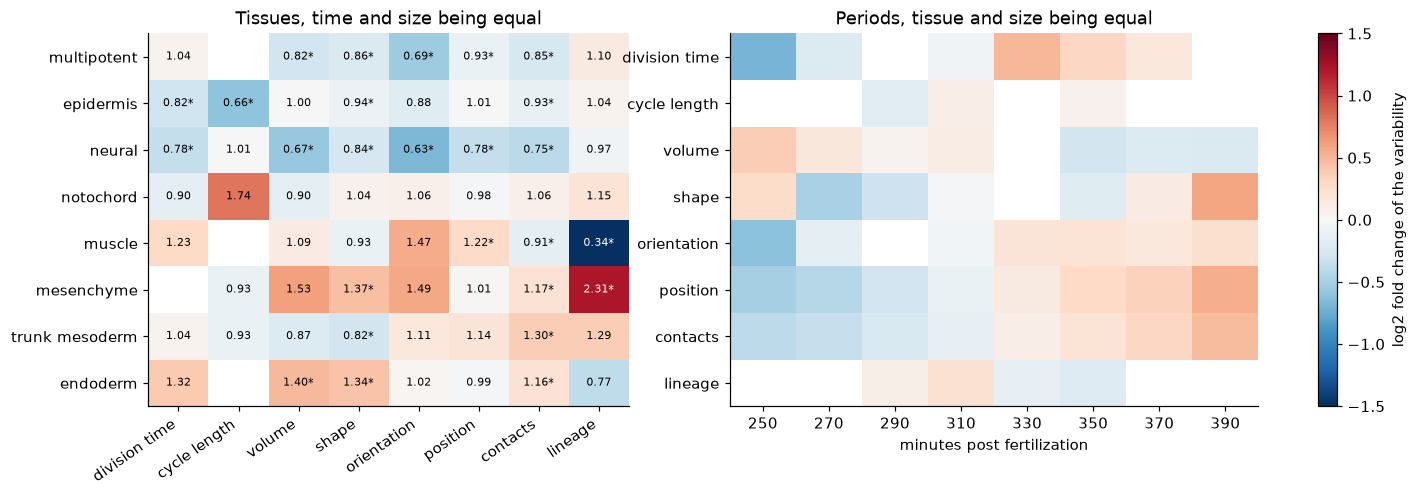

In [23]:
fold = pd.DataFrame({name: e[e.factor == "tissue"].set_index("level").fold for name, e in effects.items()}).reindex(TISSUES)
significant = pd.DataFrame({name: e[e.factor == "tissue"].set_index("level").pipe(lambda s: (s.low > 1) | (s.high < 1))
                            for name, e in effects.items()}).reindex(TISSUES)
period_fold = pd.DataFrame({name: e[e.factor == "period"].set_index("level").fold for name, e in effects.items()})
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
image = ax.imshow(np.log2(fold.to_numpy(dtype=float)), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
for i in range(fold.shape[0]):
    for j in range(fold.shape[1]):
        value = fold.iat[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value:.2f}" + ("*" if significant.iat[i, j] else ""), ha="center", va="center", fontsize=7,
                    color="white" if abs(np.log2(value)) > 1 else "black")
ax.set_xticks(range(fold.shape[1]), fold.columns, rotation=35, ha="right")
ax.set_yticks(range(fold.shape[0]), fold.index)
ax.set_title("Tissues, time and size being equal")
image2 = ax2.imshow(np.log2(period_fold.T.to_numpy(dtype=float)), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax2.set_yticks(range(period_fold.shape[1]), period_fold.columns)
ax2.set_xticks(range(period_fold.shape[0]), [f"{p:.0f}" for p in period_fold.index], rotation=0)
ax2.set(title="Periods, tissue and size being equal", xlabel="minutes post fertilization")
plt.colorbar(image2, ax=[ax, ax2], label="log2 fold change of the variability", fraction=0.02)
plt.show()

### Conclusions

**When.** The late cleavages (64 to 112 cells, 240 to 285 minutes) are
the most reproducible part of the window, in timing, orientation, position
and contacts. From the onset of gastrulation, the positions of the cells
become steadily less reproducible, twice as variable by 390 minutes, with
the embryos also starting to differ as a whole. Division timing becomes
less precise after the 112-cell stage. The apparent rises of volume and
contact variability are not changes in reproducibility. They come from
cells becoming smaller and having more, smaller contacts.

**Where.** Variability follows the germ layers:

- **Ectoderm:** the outer cells, which stay at the surface, are the most
  reproducible. The neural plate is the most precise tissue of the embryo,
  and the epidermis the most precise in timing.
- **Endoderm and mesoderm:** the inner cells, which move in during
  gastrulation, are the most variable in contacts, shape and volume.
- **Mesenchyme:** the most variable lineages, even without B7.7.

**How.** Variability is mostly cell by cell rather than embryo by embryo.
A cell's timing deviation is not passed on to its daughters, but it is
shared with its sister, its bilateral homologue and, to a lesser extent,
the cells of its tissue.

| | literature | this notebook |
|---|---|---|
| neural plate | division orientations the least variable (Biasuz et al. 2025) | least variable in 6 of 8 measures, orientation at 0.63 |
| orientation over time | more variable from generation 7 to 8 (Biasuz et al.) | 0.65 at 250 minutes, about 1.15 after 330 minutes |
| contacts | about 20% of the surface different between embryos (Biasuz et al.) | 13% at 250 minutes to 26% at 390 minutes, as cells get more small contacts |
| sides and embryos | comparable variability (Guignard et al. 2020) | three quarters of the variance of contacts, half to two thirds of that of positions, is found between the two sides of one embryo |
| A7.2, B7.2 | bimodal orientation, high dispersion (Biasuz et al.) | among the most variable cells |

**Limits.**

- **A short window:** seven embryos, compared from about 250 to 390
  minutes, from the 64-cell stage to the mid gastrula. Neurulation and the
  tailbud are seen in one embryo only, with fewer and fewer named cells.
- **Tissues from names:** the tissues are the fates of the descendants,
  read from the fate map through the names.
- **Naming bias:** the names were given by matching neighbourhoods, which
  can make contacts and positions look more alike than they are. Internal
  cells were harder to name; swapped sisters do not explain their
  variability, but other errors may contribute.
- **Coarse timing:** the 2-minute time points set a floor on timing and
  make the left/right timing baseline optimistic.
- **Overlapping factors:** size, time and tissue overlap. The model
  separates them only as far as cells of different sizes are seen at the
  same time.
- **Inference:** with seven embryos, the intervals are coarse. The
  conclusions are about these cells, which are the same in every embryo.